# Fiche 3 — Corrélation de Pearson, de Spearman, et ce qu'elles ne disent pas

| | |
|---|---|
| 🎯 **Objectif** | Choisir le bon coefficient et l'utiliser pour repérer des indicateurs redondants |
| ⏱️ **Durée** | 45 min |
| 🧰 **Prérequis** | Fiche 2 (tableau pays × indicateurs) |
| 🔗 **Dans le projet** | Exercice partie 3, étape 1 |

> **L'idée clé.** Une corrélation mesure **à quel point deux variables évoluent ensemble**, sur une échelle de
> -1 à +1. Si deux indicateurs évoluent presque parfaitement ensemble, connaître l'un suffit : le second est
> **redondant**.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from edstats import viz
from edstats.io import load_tables

viz.apply_style()
pd.set_option("display.max_colwidth", 70)

rng = np.random.default_rng(0)

## 1. Quatre situations pour tout comprendre

On fabrique des données dont on **connaît** la vraie relation, puis on regarde ce que disent les deux coefficients.

In [2]:
n = 60
x = rng.uniform(1, 10, n)  # 60 valeurs au hasard entre 1 et 10
bruit = rng.normal(0, 1.5, n)  # petites perturbations aléatoires, pour que ce ne soit pas une droite parfaite

lineaire = 2 * x + bruit
courbe = np.exp(x / 1.5) + rng.normal(0, 5, n)  # monte toujours, mais de plus en plus vite
avec_extreme = lineaire.copy()
avec_extreme[-1] = -60  # on remplace le dernier point par une valeur extrême
en_u = (x - 5.5) ** 2 + rng.normal(0, 1, n)  # descend puis remonte

cas = {"1. Linéaire": lineaire, "2. Monotone non linéaire": courbe,
       "3. Linéaire + 1 valeur extrême": avec_extreme, "4. En U (non monotone)": en_u}

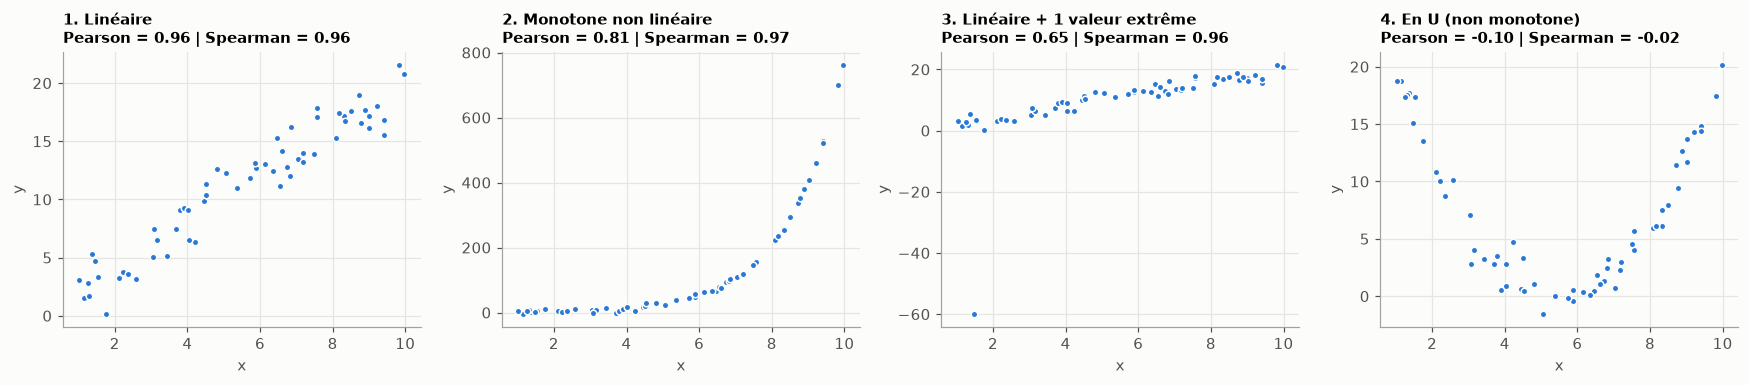

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, (titre, y) in zip(axes, cas.items()):
    pearson = pd.Series(x).corr(pd.Series(y))
    spearman = pd.Series(x).corr(pd.Series(y), method="spearman")
    ax.scatter(x, y, s=18, color=viz.BLUE, edgecolor=viz.SURFACE)
    ax.set_title(f"{titre}\nPearson = {pearson:.2f} | Spearman = {spearman:.2f}", fontsize=10)
    ax.set(xlabel="x", ylabel="y")
fig.tight_layout()
plt.show()

| Cas | Pearson | Spearman | Leçon |
|---|---|---|---|
| 1. Linéaire | 0,96 | 0,96 | les deux sont d'accord |
| 2. Monotone courbe | 0,81 | 0,97 | **Spearman** capte « quand x monte, y monte », même si ce n'est pas une droite |
| 3. Une valeur extrême | chute à 0,66 | reste à 0,96 | **un seul pays** (Chine, Inde…) suffit à fausser Pearson |
| 4. En U | ≈ -0,1 | ≈ -0,1 | **une corrélation nulle ne veut pas dire « aucun lien »** : elle veut dire « pas de lien monotone » |

**Comment ça marche ?** Spearman = Pearson calculé sur les **rangs** (1ᵉʳ, 2ᵉ, 3ᵉ…) au lieu des valeurs : un
pays 100 fois plus peuplé que le 2ᵉ n'est « que » 1ᵉʳ.

In [4]:
valeurs = pd.DataFrame({"x": [1, 2, 3, 4, 100], "y": [2, 4, 5, 9, 10]})
print("Pearson sur les valeurs :", round(valeurs.corr().iloc[0, 1], 3))
print("Pearson sur les rangs   :", round(valeurs.rank().corr().iloc[0, 1], 3))
print("Spearman sur les valeurs:", round(valeurs.corr(method="spearman").iloc[0, 1], 3), " ← identique")

Pearson sur les valeurs : 0.678
Pearson sur les rangs   : 1.0
Spearman sur les valeurs: 1.0  ← identique


## 2. Sur les vraies données

0.93 (Pearson)
0.79 (Spearman)


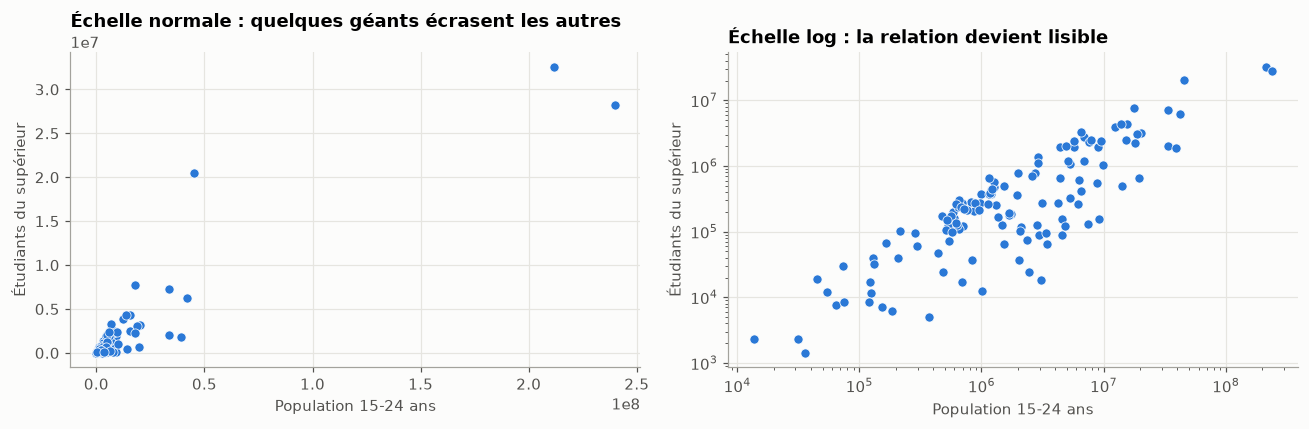

In [5]:
pays_indicateurs = pd.read_csv("../data/processed/pays_indicateurs.csv", index_col=0)
paire = ["Population 15-24 ans", "Étudiants du supérieur"]
print(pays_indicateurs[paire].corr(method="pearson").iloc[0, 1].round(2), "(Pearson)")
print(pays_indicateurs[paire].corr(method="spearman").iloc[0, 1].round(2), "(Spearman)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=pays_indicateurs, x=paire[0], y=paire[1], ax=axes[0], color=viz.BLUE)
axes[0].set_title("Échelle normale : quelques géants écrasent les autres")
sns.scatterplot(data=pays_indicateurs, x=paire[0], y=paire[1], ax=axes[1], color=viz.BLUE)
axes[1].set(xscale="log", yscale="log", title="Échelle log : la relation devient lisible")
fig.tight_layout()
plt.show()

Ici, c'est l'inverse du cas 3 : Pearson (0,93) **dépasse** Spearman (0,79). Les géants (Inde, Chine) sont
extrêmes **sur les deux axes à la fois** et alignés : ils « tirent » la droite et gonflent Pearson. Une valeur extrême
peut donc aussi bien **gonfler** que **dégonfler** Pearson. Spearman, lui, regarde le classement des 180 pays et
donne une image plus fidèle de la relation pour un pays typique.

⚠️ **Piège : les valeurs manquantes.** `corr()` calcule chaque coefficient sur les pays où **les deux** valeurs
existent. Deux coefficients d'une même matrice peuvent donc porter sur des pays différents :

In [6]:
print("pays dans le fichier :", len(pays_indicateurs))
print("pays où les DEUX valeurs existent :", pays_indicateurs[paire].dropna().shape[0])

pays dans le fichier : 216
pays où les DEUX valeurs existent : 130


Le coefficient ci-dessus porte donc sur 130 pays, pas sur 216. Une autre paire de la même matrice peut porter sur
d'autres pays : il faut le savoir avant de comparer deux coefficients.

## 3. Corrélation n'est pas causalité

Le taux d'internet et le taux de scolarisation dans le supérieur sont très corrélés (ρ ≈ 0,8). Cela ne veut pas
dire qu'installer internet fait aller à l'université. Regarde le lien de chacun avec la richesse du pays :

In [7]:
s = pays_indicateurs.select_dtypes("number").corr(method="spearman")
pib = "PIB par habitant (PPA, $ int.)"
s.loc[pib, ["Utilisateurs d'internet (% population)", "Taux brut de scolarisation supérieure (%)"]].round(2)

Utilisateurs d'internet (% population)       0.91
Taux brut de scolarisation supérieure (%)    0.79
Name: PIB par habitant (PPA, $ int.), dtype: float64

Les deux sont fortement liés au PIB par habitant : un **facteur commun** (la richesse) peut suffire à expliquer
qu'ils montent ensemble. Ce calcul ne *prouve* pas que la richesse est la cause, il montre seulement qu'une autre
explication que « internet → université » existe. Pour la sélection d'indicateurs, cela n'a pas d'importance : on
veut seulement savoir si l'un **renseigne** sur l'autre.

## 4. Visualiser une matrice : la heatmap

Une matrice de 15 × 15 nombres est illisible. Une **heatmap** colore chaque case :

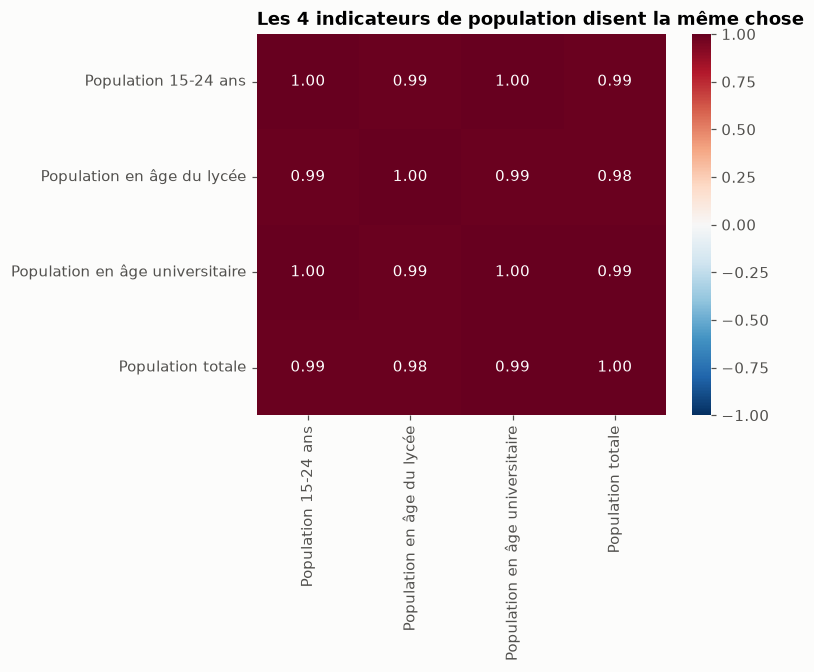

In [8]:
population = ["Population 15-24 ans", "Population en âge du lycée", "Population en âge universitaire",
              "Population totale"]
m = pays_indicateurs[population].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(m, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Les 4 indicateurs de population disent la même chose")
plt.show()

- `annot=True` écrit la valeur dans chaque case, `fmt=".2f"` l'arrondit à 2 décimales.
- `vmin=-1, vmax=1` fixe l'échelle : **blanc = 0**, bleu = négatif, rouge = positif, quelle que soit la matrice.
  Sans cela, seaborn étire les couleurs sur les valeurs présentes, et 0,95 pourrait sembler « faible ».

## 5. De la corrélation à la redondance

D'abord à la main : on parcourt la moitié haute de la matrice (chaque paire une seule fois) et on garde les paires
au-delà du seuil.

In [9]:
colonnes = list(m.columns)
for i, a in enumerate(colonnes):
    for b in colonnes[i + 1:]:  # seulement les paires (a, b) avec b après a
        if abs(m.loc[a, b]) >= 0.7:
            print(f"{a}  ↔  {b} : {m.loc[a, b]:.2f}")

Population 15-24 ans  ↔  Population en âge du lycée : 0.99
Population 15-24 ans  ↔  Population en âge universitaire : 1.00
Population 15-24 ans  ↔  Population totale : 0.99
Population en âge du lycée  ↔  Population en âge universitaire : 0.99
Population en âge du lycée  ↔  Population totale : 0.98
Population en âge universitaire  ↔  Population totale : 0.99


La fonction `redundant_pairs` du projet fait la même chose sur toute la matrice et trie le résultat :

In [10]:
from edstats.analysis import redundant_pairs

spearman = pays_indicateurs.select_dtypes("number").corr(method="spearman")
redundant_pairs(spearman, threshold=0.7).head(8).round(2)

,var_1,var_2,correlation
0,Population 15-24 ans,Population en âge universitaire,1.00
1,Population en âge universitaire,Population totale,0.99
2,Population en âge du lycée,Population en âge universitaire,0.99
3,Population 15-24 ans,Population en âge du lycée,0.99
4,Population 15-24 ans,Population totale,0.99
5,Population en âge du lycée,Population totale,0.98
6,Population totale,Élèves du secondaire,0.98
7,"PIB par habitant (PPA, $ int.)","RNB par habitant (Atlas, $ US)",0.98


Dans chaque paire, on garde **l'indicateur le plus utile pour le métier**. Ce n'est pas une décision statistique :
c'est pour cela que le corrigé parcourt les indicateurs par **ordre de priorité métier** (`select_non_redundant`).

### ✍️ À toi de jouer

Sur le modèle du § 4, trace la heatmap de Spearman entre ces 4 indicateurs : internet, PIB par habitant (PPA), taux de scolarisation supérieure, part des 0-14 ans. Pourquoi la part des 0-14 ans est-elle **négativement** corrélée aux trois autres ?

In [11]:
# Ta réponse ici

<details>
<summary><b>💡 Voir une solution</b> (après avoir cherché !)</summary>

```python
cols = ["Utilisateurs d'internet (% population)", "PIB par habitant (PPA, $ int.)",
        "Taux brut de scolarisation supérieure (%)", "Part des 0-14 ans (%)"]
sns.heatmap(pays_indicateurs[cols].corr(method="spearman"), annot=True, fmt=".2f",
            cmap="RdBu_r", vmin=-1, vmax=1)
```

Les pays riches ont fait leur transition démographique : moins d'enfants, donc une population plus âgée. Un coefficient négatif signale une relation **inverse**, pas une absence de relation. Pour la redondance, c'est la **valeur absolue** qui compte.
</details>

## ✅ À retenir

1. **Pearson** : relation linéaire, sensible aux valeurs extrêmes. **Spearman** : relation monotone, calculée sur les rangs, robuste.
2. Données très asymétriques (populations, PIB) : on préfère Spearman.
3. r ≈ 0 ne signifie pas « aucun lien » (cas du U).
4. `corr()` ignore les NaN **paire par paire** : vérifier sur combien de pays porte chaque coefficient.
5. Redondance = |r| élevé ; on tranche par le **métier**, pas par la statistique.
6. Corrélation ≠ causalité.